<div style=" background-color: RGB(0,114,200);" >
<h1 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">PROJET 6 DATA ANALYST</h1>
<h2 style="margin: auto; padding: 20px 0; color:#fff; text-align: center">Analysez les ventes d'une librairie avec R ou Python
</h2>
</div>

L’entreprise Lapage était originellement une librairie physique avec plusieurs points de vente. Mais devant le succès de certains de ses produits et l’engouement de ses clients, elle a décidé depuis 2 ans d’ouvrir un site de vente en ligne.
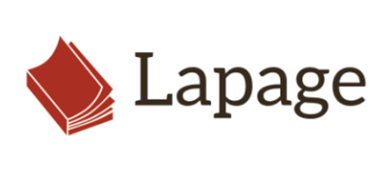

La structure a besoin d’aide pour mieux comprendre ses données, c’est pourquoi elle a recruté un Data Analyst afin de faire le point sur l’activité. 

L’équipe Marketing se compose de : 
+ Annabelle, responsable Marketing ;
+ Julie, Business Intelligence Analyst ;
+ Antoine, Business Analyst;
+ Christelle (moi), Data Analyst.

# Missions
Cette analyse va être découpée en deux parties :

+ Une analyse des différents indicateurs de vente, qui a été demandée directement par Antoine. 
+ Une analyse plus ciblée sur les clients : l’objectif est de comprendre le comportement de nos clients en ligne, pour pouvoir ensuite comparer avec la connaissance acquise via nos librairies physiques (A voir avec Julie)


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 1 - Importation des librairies et chargement des fichiers</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.1 - Importation des librairies et création des fonctions</h3>
</div>

# Importation des librairies 

In [1]:
# Importation de la librairie Pandas pour la manipulation des dataframes
import pandas as pd

# Importation de la librairie Numpy pour faire la courbe de Lorenz
import numpy as np

# Importation de la librairie Matplotlib pour la conception des graphiques
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Importation de la librairie Seaborn pour la conception des graphiques (ex: Boxplot et nuage de point)
import seaborn as sns

# Importation de la librairie scipy pour la courbe de Lorenz et les tests statistiques
import scipy.stats as st
from scipy.stats import cumfreq
from scipy.stats import chi2_contingency #test de chi2
from scipy.stats import spearmanr #Coefficient de corrélation de Spearman
from scipy.stats import kstest #Test de normalité Kolmogorov Smirnov
from scipy.stats import kruskal #Test de Kruskal-Wallis

# Importation de la librairie statsmodels pour analyse de la tendance et saisonnalité
import statsmodels.api as sm



# Création fonction

In [2]:
# Fonction pour importer un fichier csv
def importer_csv(chemin, nom_fichier):
    chemin_complet = chemin + "/" + nom_fichier
    data = pd.read_csv(chemin_complet, delimiter=";")
    return data


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">1.2 - Chargement des fichiers Excel</h3>
</div>

In [3]:
# Importer les 3 fichiers CSV
chemin = "BDD"

# Importation du fichier Customer
customer = importer_csv(chemin, "customers.csv")

# Importation du fichier Products
product = importer_csv(chemin, "products.csv")

# Importation du fichier Transactions
transaction = importer_csv(chemin, "Transactions.csv")


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 2 - Analyse exploratoire</h2>
</div>

<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.1 - Analyse exploratoire du fichier Customer</h3>
</div>

In [4]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes
# Le nombre de valeurs présentes dans chacune des colonnes
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8621 entries, 0 to 8620
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   client_id  8621 non-null   object
 1   sex        8621 non-null   object
 2   birth      8621 non-null   int64 
dtypes: int64(1), object(2)
memory usage: 202.2+ KB


Il n'y a pas de valeur manquante.

In [5]:
# Affichage des informations sur les colonnes numériques
customer.describe()

,birth
count,8621.000000
mean,1978.275606
std,16.917958
min,1929.000000
25%,1966.000000
50%,1979.000000
75%,1992.000000
max,2004.000000


+ L'âge max d'un client est de 95 ans
+ L'âge min d'un client est de 20 ans

In [6]:
# Vérification de l'unicité de la clé primaire 
print("{} doublon(s)".format(customer.duplicated().sum()))

0 doublon(s)


La clé primaire de la table "customer" est "client_id" => Pas de doublon => UNICITE = OK

In [7]:
# Calcul de l'âge dans une nouvelle colonne parce que ce sera utile pour la suite de l'analyse
customer['age'] = 2024 - customer['birth'] 

In [8]:
# Affichage des 10 premières lignes
customer.head(10)

,client_id,sex,birth,age
0,c_4410,f,1967,57
1,c_7839,f,1975,49
2,c_1699,f,1984,40
3,c_5961,f,1962,62
4,c_5320,m,1943,81
5,c_415,m,1993,31
6,c_285,f,1967,57
7,c_160,f,1978,46
8,c_6446,m,1971,53
9,c_6866,m,1993,31


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.2 - Analyse exploratoire du fichier Product</h3>
</div>

In [9]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes
# Le nombre de valeurs présentes dans chacune des colonnes
product.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3286 entries, 0 to 3285
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   id_prod  3286 non-null   object 
 1   price    3286 non-null   float64
 2   categ    3286 non-null   int64  
dtypes: float64(1), int64(1), object(1)
memory usage: 77.1+ KB


Il n'y a pas de valeur manquante.

In [10]:
# Affichage des informations sur les colonnes numériques
product.describe()

,price,categ
count,3286.000000,3286.000000
mean,21.863597,0.370359
std,29.849786,0.615446
min,0.620000,0.000000
25%,6.990000,0.000000
50%,13.075000,0.000000
75%,22.990000,1.000000
max,300.000000,2.000000


In [11]:
# Vérification de l'unicité de la clé primaire 
print("{} doublon(s)".format(product.duplicated().sum()))

0 doublon(s)


La clé primaire de la table "product" est "id_prod" => Pas de doublon => UNICITE = OK

In [12]:
# Affichage des 10 premières lignes
product.head(10)

,id_prod,price,categ
0,0_1421,19.99,0
1,0_1368,5.13,0
2,0_731,17.99,0
3,1_587,4.99,1
4,0_1507,3.99,0
5,0_1163,9.99,0
6,1_463,36.99,1
7,0_2157,34.99,0
8,0_1915,16.99,0
9,0_389,18.99,0


<div style="border: 1px solid RGB(0,150,250);" >
<h3 style="margin: auto; padding: 20px; color: RGB(0,150,250); ">2.3 - Analyse exploratoire du fichier Transaction</h3>
</div>

In [13]:
# Consulter le nombre de colonnes
# La nature des données dans chacune des colonnes
# Le nombre de valeurs présentes dans chacune des colonnes
transaction.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 687534 entries, 0 to 687533
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   id_prod     687534 non-null  object
 1   date        687534 non-null  object
 2   session_id  687534 non-null  object
 3   client_id   687534 non-null  object
dtypes: object(4)
memory usage: 21.0+ MB


Il n'y a pas de valeur manquante.

In [14]:
# Affichage des informations sur les colonnes numériques
transaction.describe()

,id_prod,date,session_id,client_id
count,687534,687534,687534,687534
unique,3265,687419,345505,8600
top,1_369,2021-10-06 21:29:59.752585,s_118668,c_1609
freq,2340,2,14,25586


In [15]:
# Vérification de l'unicité de la clé primaire 
print("{} doublon(s)".format(product.duplicated().sum()))

0 doublon(s)


La clé primaire de la base "transaction" est "session_id" => Pas de doublon => UNICITE = OK

In [16]:
# Affichage des 10 premières lignes
transaction.head(10)

,id_prod,date,session_id,client_id
0,0_1259,2021-03-01 00:01:07.843138,s_1,c_329
1,0_1390,2021-03-01 00:02:26.047414,s_2,c_664
2,0_1352,2021-03-01 00:02:38.311413,s_3,c_580
3,0_1458,2021-03-01 00:04:54.559692,s_4,c_7912
4,0_1358,2021-03-01 00:05:18.801198,s_5,c_2033
5,0_1073,2021-03-01 00:05:44.999018,s_6,c_4908
6,0_1304,2021-03-01 00:07:04.371179,s_7,c_1609
7,0_279,2021-03-01 00:07:48.507530,s_6,c_4908
8,1_445,2021-03-01 00:09:11.523122,s_8,c_7991
9,1_556,2021-03-01 00:10:20.265265,s_9,c_6171


In [17]:
# Séparer la colonne de dates en deux colonnes distinctes : Date et Heure
transaction[['date', 'heure']] = transaction['date'].str.split(' ', expand=True)

In [18]:
# Affichage des 10 premières lignes
transaction.head(10)

,id_prod,date,session_id,client_id,heure
0,0_1259,2021-03-01,s_1,c_329,00:01:07.843138
1,0_1390,2021-03-01,s_2,c_664,00:02:26.047414
2,0_1352,2021-03-01,s_3,c_580,00:02:38.311413
3,0_1458,2021-03-01,s_4,c_7912,00:04:54.559692
4,0_1358,2021-03-01,s_5,c_2033,00:05:18.801198
5,0_1073,2021-03-01,s_6,c_4908,00:05:44.999018
6,0_1304,2021-03-01,s_7,c_1609,00:07:04.371179
7,0_279,2021-03-01,s_6,c_4908,00:07:48.507530
8,1_445,2021-03-01,s_8,c_7991,00:09:11.523122
9,1_556,2021-03-01,s_9,c_6171,00:10:20.265265


In [19]:
# Mettre la colonne date en format date
transaction['date'] = pd.to_datetime(transaction['date'])

# Faciliter la manipulation des dates:
transaction["annee"] = transaction["date"].dt.year
transaction["mois"] = transaction["date"].dt.month
transaction["jour"] = transaction["date"].dt.day
transaction["annee_mois"] = transaction["annee"].astype(str) + "-" + transaction["mois"].astype(str)

#Mettre la colonne annee-mois en format date
transaction['annee_mois'] = pd.to_datetime(transaction['annee_mois'])

In [20]:
# Min et max de date de transaction
print("Les données de vente sont limitées entre {} et {}".format(transaction['date'].min(),transaction['date'].max() ))


Les données de vente sont limitées entre 2021-03-01 00:00:00 et 2023-02-28 00:00:00


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 3 - Rapprochement des 3 fichiers</h2>
</div>

# Vérification de la synchronisation des fichiers

1) Jointure entre "transaction" et "product" 

In [21]:
# Jointure entre "transaction" et "product" 
df = pd.merge(transaction, product,indicator= True, on='id_prod', how='outer')

In [22]:
# Affichage des produits qui ne sont pas référenciés dans la table "product" mais qui a été mis en vente
df[df['_merge'] == "left_only"]

,id_prod,date,session_id,client_id,heure,annee,mois,jour,annee_mois,price,categ,_merge


Tous les produits qui sont vendus sont référenciés dans la base de données produits. 

In [23]:
# Affichage des produits qui n'ont jamais été vendu depuis le lancement de l'entreprise
df[df['_merge'] == "right_only"]

,id_prod,date,session_id,client_id,heure,annee,mois,jour,annee_mois,price,categ,_merge
687534,0_1016,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,35.06,0,right_only
687535,0_1780,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,1.67,0,right_only
687536,0_1062,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,20.08,0,right_only
687537,0_1119,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,2.99,0,right_only
687538,0_1014,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,1.15,0,right_only
687539,1_0,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,31.82,1,right_only
687540,0_1318,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,20.92,0,right_only
687541,0_1800,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,22.05,0,right_only
687542,0_1645,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,2.99,0,right_only
687543,0_322,NaT,NaN,NaN,NaN,NaN,NaN,NaN,NaT,2.99,0,right_only


In [24]:
# Commentaires
print("Il y a {:.0f} produit(s) qui n'ont jamais été vendu depuis le lancement de l'entreprise.".format(len(df[df['_merge'] == "right_only"])))

Il y a 21 produit(s) qui n'ont jamais été vendu depuis le lancement de l'entreprise.


2) Jointure entre "transaction" et "customer"

In [25]:
# Jointure entre "transaction" et "customer" 
df = pd.merge(transaction, customer,indicator= True, on='client_id', how='outer')

In [26]:
# Affichage des clients qui ne sont pas référenciés dans la table "customer" mais qui ont fait au moins une transaction
df[df['_merge'] == "left_only"]

,id_prod,date,session_id,client_id,heure,annee,mois,jour,annee_mois,sex,birth,age,_merge


Tous les clients qui ont fait au moins une transaction sont référenciés dans la base de données client. 

In [27]:
# Affichage des clients qui n'ont jamais été vendu depuis le lancement de l'entreprise
df[df['_merge'] == "right_only"]

,id_prod,date,session_id,client_id,heure,annee,mois,jour,annee_mois,sex,birth,age,_merge
687534,NaN,NaT,NaN,c_8253,NaN,NaN,NaN,NaN,NaT,f,2001,23,right_only
687535,NaN,NaT,NaN,c_3789,NaN,NaN,NaN,NaN,NaT,f,1997,27,right_only
687536,NaN,NaT,NaN,c_4406,NaN,NaN,NaN,NaN,NaT,f,1998,26,right_only
687537,NaN,NaT,NaN,c_2706,NaN,NaN,NaN,NaN,NaT,f,1967,57,right_only
687538,NaN,NaT,NaN,c_3443,NaN,NaN,NaN,NaN,NaT,m,1959,65,right_only
687539,NaN,NaT,NaN,c_4447,NaN,NaN,NaN,NaN,NaT,m,1956,68,right_only
687540,NaN,NaT,NaN,c_3017,NaN,NaN,NaN,NaN,NaT,f,1992,32,right_only
687541,NaN,NaT,NaN,c_4086,NaN,NaN,NaN,NaN,NaT,f,1992,32,right_only
687542,NaN,NaT,NaN,c_6930,NaN,NaN,NaN,NaN,NaT,m,2004,20,right_only
687543,NaN,NaT,NaN,c_4358,NaN,NaN,NaN,NaN,NaT,m,1999,25,right_only


In [28]:
# Commentaires
print("Il y a {:.0f} client(s) qui n'ont jamais acheté de livre mais qui apparaissent dans notre base de données client.".format(len(df[df['_merge'] == "right_only"])))

Il y a 21 client(s) qui n'ont jamais acheté de livre mais qui apparaissent dans notre base de données client.


# Jointures
Type de jointure interne parce que nous allons nous focaliser sur les produits vendus, donc partir de la table transaction :
+ df = Transaction + Product
+ df = df + Customer

In [29]:
# Jointures 
df = pd.merge(transaction, product, on='id_prod', how='inner')
df = pd.merge(df, customer,on='client_id', how='inner')

In [30]:
# Remplir les valeurs vides par "0"
df['price'] = df['price'].fillna(0)

In [31]:
# Affichage des 10 premières lignes
df.head(10)

,id_prod,date,session_id,client_id,heure,annee,mois,jour,annee_mois,price,categ,sex,birth,age
0,0_1259,2021-03-01,s_1,c_329,00:01:07.843138,2021,3,1,2021-03-01,11.99,0,f,1967,57
1,0_1259,2022-10-01,s_275943,c_329,00:01:07.843138,2022,10,1,2022-10-01,11.99,0,f,1967,57
2,0_1259,2022-12-01,s_305291,c_329,00:01:07.843138,2022,12,1,2022-12-01,11.99,0,f,1967,57
3,0_1259,2023-01-01,s_320153,c_329,00:01:07.843138,2023,1,1,2023-01-01,11.99,0,f,1967,57
4,1_397,2021-11-23,s_123998,c_329,18:21:56.361813,2021,11,23,2021-11-01,18.99,1,f,1967,57
5,1_397,2022-04-23,s_198364,c_329,18:21:56.361813,2022,4,23,2022-04-01,18.99,1,f,1967,57
6,0_1140,2021-03-16,s_7071,c_329,10:01:30.705174,2021,3,16,2021-03-01,3.73,0,f,1967,57
7,0_1140,2022-11-16,s_298327,c_329,10:01:30.705174,2022,11,16,2022-11-01,3.73,0,f,1967,57
8,1_451,2021-03-18,s_8134,c_329,17:26:18.887580,2021,3,18,2021-03-01,20.99,1,f,1967,57
9,1_378,2021-07-23,s_66215,c_329,18:52:04.044752,2021,7,23,2021-07-01,26.61,1,f,1967,57


<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 4 - Analyse des différents indicateurs de vente (Antoine)</h2>
</div>

# Chiffre d'affaires et nombre de vente global

In [32]:
# Calcul du Chiffre d'affaires total
print('CA Total = {:.0f} €'.format(df['price'].sum()))

CA Total = 12027663 €


In [33]:
# Calcul du nombre de vente
print('Nombre de vente = {:.0f}'.format(df['session_id'].nunique()))

Nombre de vente = 345505


# Chiffre d'affaires par catégorie

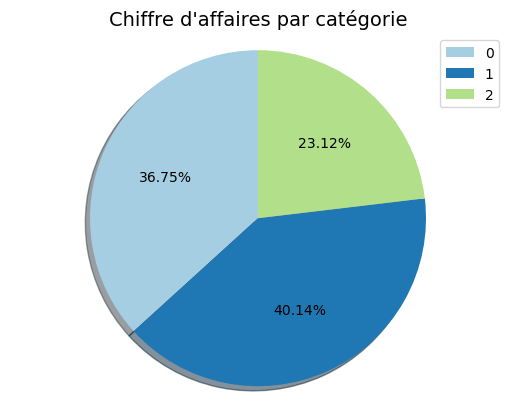

In [34]:
# Calcul du CA par catégorie
CA_categ = df.groupby('categ')[['price']].sum().reset_index()

# Renommer la colonne price en CA
CA_categ = CA_categ.rename(columns={"price" : "CA"}) 

#Affichage de la répartition du CA par catégorie dans un Pie chart
# Récupération des données
proportion = CA_categ['CA'].values
labels = CA_categ['categ'].values

# Obtenir la réf de couleur à utiliser
col_map = plt.get_cmap('Paired')

# Création du graph
fig, ax = plt.subplots()
ax.pie(proportion, autopct='%1.2f%%', shadow=True, startangle=90, colors=col_map.colors)
ax.axis('equal')
plt.legend(labels)
plt.title("Chiffre d'affaires par catégorie", fontsize=14)

# Afficher le graph
plt.show()

# Evolution du chiffre d'affaires dans le temps

In [35]:
# CA annuel:
ca_annuel = df.groupby(["annee"])["price"].sum()
print("Chiffres d'affaires annuels:\n", ca_annuel)

# Nombre de ventes annuel:
ventes_annuelles = df.groupby(["annee"])["session_id"].count()
print("Nombre de ventes annuelles:\n", ventes_annuelles)

Chiffres d'affaires annuels:
 annee
2021    4944760.98
2022    6108681.81
2023     974220.31
Name: price, dtype: float64
Nombre de ventes annuelles:
 annee
2021    286671
2022    346380
2023     54483
Name: session_id, dtype: int64


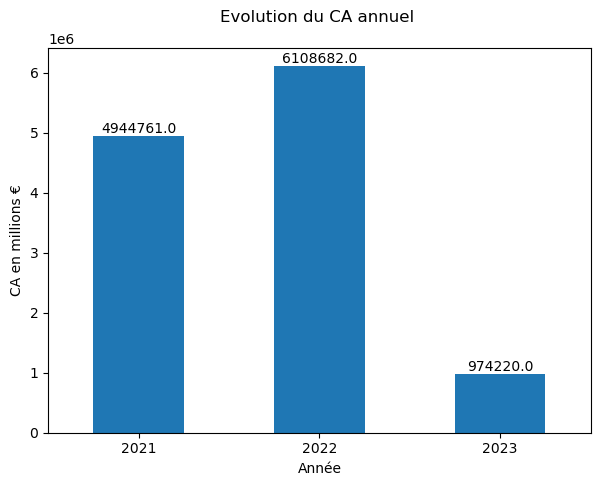

In [36]:
# Visualisation du CA Annuel
plt.figure(figsize = (7,5))
ca_annuel.plot.bar(x='annee', y='C_A')
plt.xlabel('Année')
plt.xticks(rotation=0)
plt.ylabel('CA en millions €')
plt.title('Evolution du CA annuel \n')

# Ajouter une étiquette de données à chaque barre
ca_annuel = ca_annuel.reset_index()
for i, v in enumerate(ca_annuel['price']):
    plt.text(i, v, round(v, 0), ha='center', va='bottom')


+ La meilleure année en terme de CA et de nombre de vente est l'année 2022, tout en sachant que les données à notre disposition sont comprises entre 01/03/2021 et 28/02/2023.
+ De ce fait, la comparaison annuelle ne nous permet pas d'évaluer les tendances parce que les données 2021 et 2023 ne sont pas complètes. Il serait préférable de faire une analyse mensuellement afin d'identifier une tendance.

# Décomposition en moyenne mobile du Chiffre d'affaires

In [37]:
# Calcul chiffre d'affaires mensuel
ca_mensuel = df.groupby(["annee_mois"])["price"].sum().reset_index()

In [38]:
# Calculer la moyenne mobile sur une fenêtre de 3 périodes
ca_mensuel['moyenne_mobile'] = ca_mensuel["price"].rolling(3).mean()

Text(0.5, 1.0, 'CA mensuel et Moyenne mobile \n')

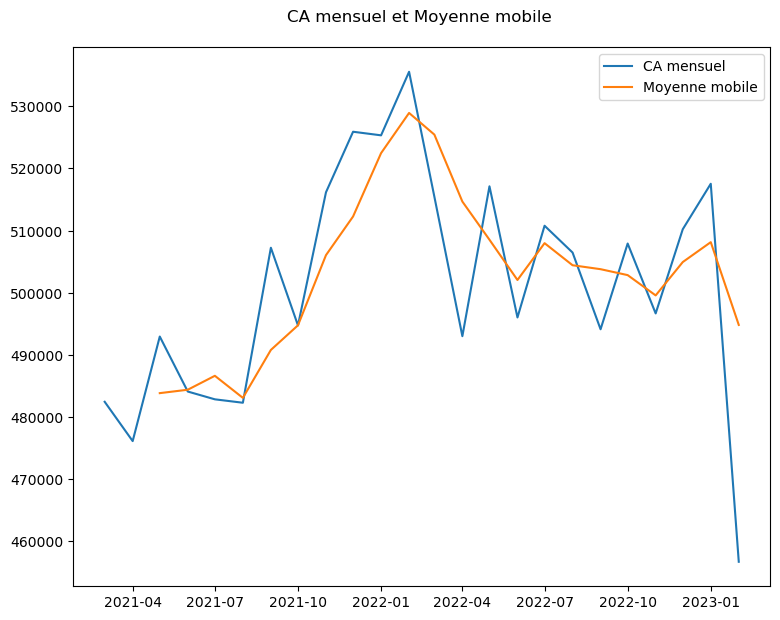

In [39]:
# Visualisation de la moyenne mobile
# Créer un graphique avec la courbe d'origine et la moyenne mobile
plt.figure(figsize=[9,7])
plt.plot(ca_mensuel['annee_mois'], ca_mensuel['price'], label='CA mensuel')
plt.plot(ca_mensuel['annee_mois'], ca_mensuel['moyenne_mobile'], label='Moyenne mobile')

# Ajouter une légende et un titre au graphique
plt.legend()
plt.title('CA mensuel et Moyenne mobile \n')


Il n'y a pas de tendance qui se dégage de la série temporelle.

In [40]:
# Calcul chiffre d'affaires mensuel par catégorie
ca_categ_mensuel = df.groupby(["annee_mois","categ"])["price"].sum().reset_index()
ca_categ_mensuel = ca_categ_mensuel.pivot_table(index='annee_mois', columns='categ', values='price', aggfunc='sum')

Text(0.5, 1.0, "Evolution du chiffre d'affaires par catégorie")

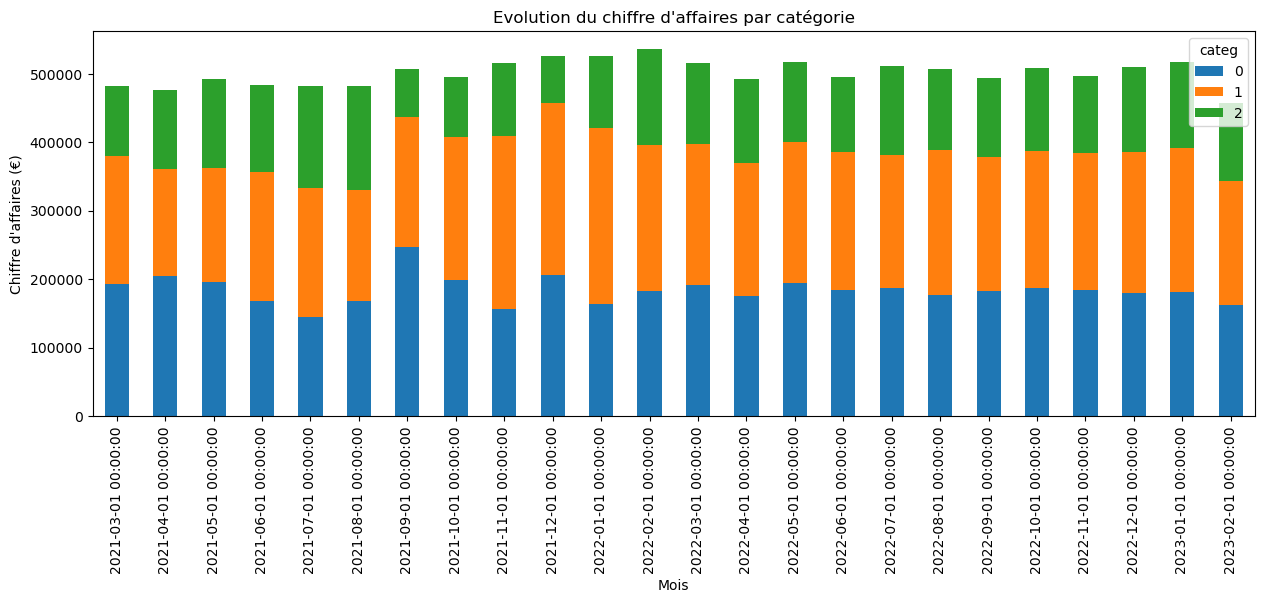

In [41]:
# Visualisation du CA par mois par catégorie
ca_categ_mensuel.plot.bar(figsize=(15,5), stacked=True)
plt.xlabel('Mois')
plt.xticks(rotation=90)
plt.ylabel("Chiffre d'affaires (€)")

plt.title("Evolution du chiffre d'affaires par catégorie")

Il n'y a pas de tendance qui se dégage du graphique en barre. Nous allons approfondir l'analyse en calculant le chiffre d'affaires par jour

In [42]:
# Calcul chiffre d'affaires par jour
ca_jour = df.groupby(["date"])["price"].sum().reset_index()
ca_jour = ca_jour.sort_values('date')
ca_jour

,date,price
0,2021-03-01,16565.22
1,2021-03-02,15486.45
2,2021-03-03,15198.69
3,2021-03-04,15196.07
4,2021-03-05,17471.37
...,...,...
725,2023-02-24,15207.89
726,2023-02-25,15761.25
727,2023-02-26,16304.72
728,2023-02-27,19170.81


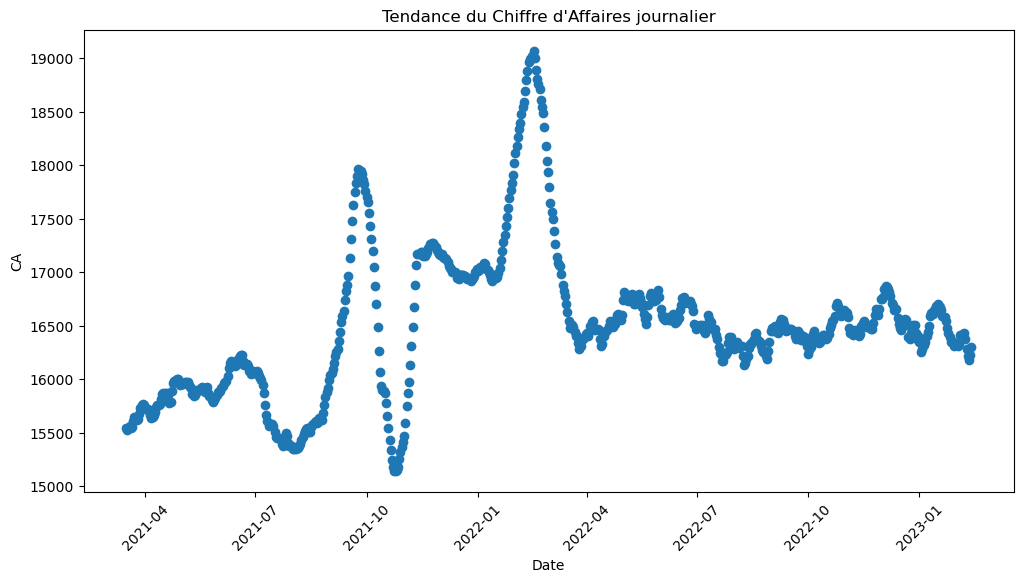

In [43]:
# Analyse de la tendance et de la saisonnalité
decomposition = sm.tsa.seasonal_decompose(ca_jour['price'], model='additive', period=30)
trend = decomposition.trend
seasonal = decomposition.seasonal

# Visualisation de la tendance
plt.figure(figsize=(12, 6))
plt.plot_date(ca_jour['date'], trend)

plt.title('Tendance du Chiffre d\'Affaires journalier')
plt.xlabel('Date')
plt.ylabel('CA')
plt.xticks(rotation=45)  # Rotation de 45 degrés pour les étiquettes de date

plt.show()


In [44]:
# Zoom sur la période : Du 01/07/2021 au 31/03/2022
#Création d'un dataframe pour approfondir l'analyse
ca_categ_jour = df.groupby(["date","categ"])["price"].sum().reset_index()
ca_categ_jour_subset = ca_categ_jour[ca_categ_jour['date'].between('2021-07-01', '2022-03-31')]


ca_categ_jour = ca_categ_jour_subset.pivot_table(index='date', columns='categ', values='price', aggfunc='sum')

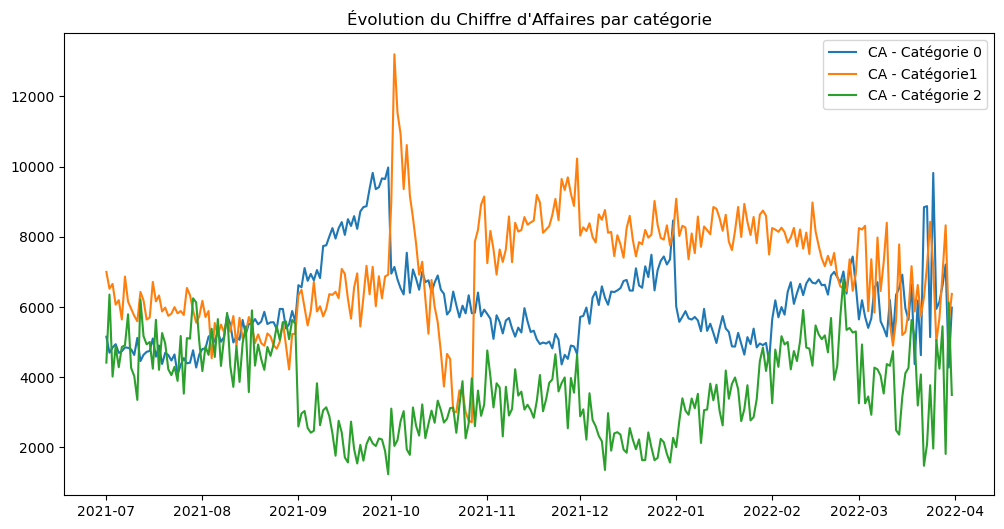

In [45]:
# Visualisation du CA par catégorie

ca_categ_jour=ca_categ_jour.reset_index()

# Créer une figure avec une taille spécifique
plt.figure(figsize=(12, 6))

# Tracer les courbes
plt.plot(ca_categ_jour['date'], ca_categ_jour[0], label='CA - Catégorie 0')
plt.plot(ca_categ_jour['date'], ca_categ_jour[1], label='CA - Catégorie1')
plt.plot(ca_categ_jour['date'], ca_categ_jour[2], label='CA - Catégorie 2')

# Ajouter une légende et des titres
plt.legend()
plt.title('Évolution du Chiffre d\'Affaires par catégorie')

# Afficher le graphique
plt.show()

+ A première vue, la tendance du CA total entre le mois d’octobre et novembre 2021 correspond à la tendance des livres de catégorie 1 qui est en baisse. Cet évènement est peut-être dû à une rupture de stock parce qu'il y avait un pic de vente début octobre.

+ Quand le chiffre d'affaires des livres de catégorie 2 est en hausse, cela présente un impact positif significatif sur le chiffre d'affaires total.


# TOP et FLOP par référence produit

In [46]:
# Calcul du CA par référence produit 
CA_produit = df.groupby(["id_prod"])["price"].sum()

<Figure size 700x500 with 0 Axes>

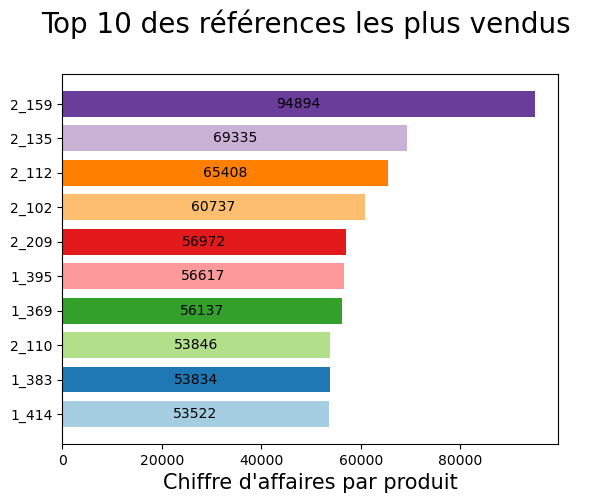

In [47]:
# Visualisation du TOP 10 produits
top10_produit = CA_produit.nlargest(10).reset_index()
top10_produit = top10_produit.sort_values(by='price', ascending=True)

# Affichage des Tops référence dans un graphique à barre horizontale
produit = top10_produit['id_prod'].values
CA = top10_produit['price'].values

 
# Ajuster la taille de l'image et obtenir la réf de couleur à utiliser
plt.figure(figsize=[7,5])
col_map = plt.get_cmap('Paired')

# Création de la graphique avec titre,légende des axes et étiquettes des données
fig, ax = plt.subplots()
hbars = plt.barh(produit,CA , height=0.75, color=col_map.colors)
ax.set_xlabel("Chiffre d'affaires par produit", fontsize=15)
ax.set_title("Top 10 des références les plus vendus \n", fontsize=20)
ax.bar_label(hbars, fmt='%.0f', label_type='center')

# Afficher le graph
plt.show()

La majorité du TOP 10 des références les plus vendus sont des livres de catégorie "2". Ce qui explique l'impact positif significatif du CA des livres de catégorie 2 au CA total.

<Figure size 700x500 with 0 Axes>

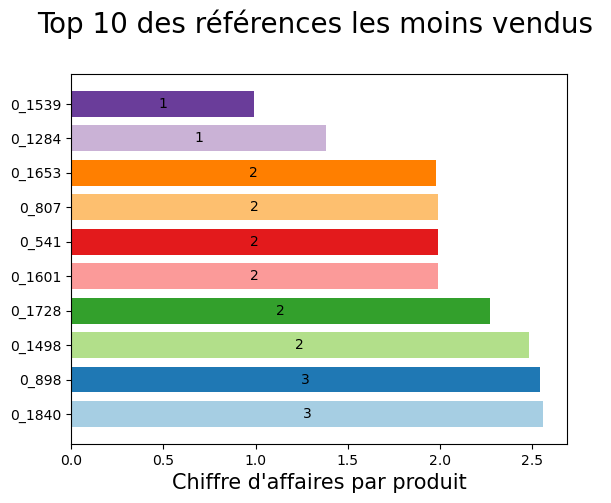

In [76]:
# TOP 10 des produits les moins vendus en terme de chiffre d'affaires
flop10_produit = CA_produit.nsmallest(10).reset_index()
flop10_produit = flop10_produit.sort_values(by='price', ascending=False)

# Affichage des Tops référence dans un graphique à barre horizontale
produit = flop10_produit['id_prod'].values
CA = flop10_produit['price'].values

 
# Ajuster la taille de l'image et obtenir la réf de couleur à utiliser
plt.figure(figsize=[7,5])
col_map = plt.get_cmap('Paired')

# Création de la graphique avec titre,légende des axes et étiquettes des données
fig, ax = plt.subplots()
hbars = plt.barh(produit,CA , height=0.75, color=col_map.colors)
ax.set_xlabel("Chiffre d'affaires par produit", fontsize=15)
ax.set_title("Top 10 des références les moins vendus \n", fontsize=20)
ax.bar_label(hbars, fmt='%.0f', label_type='center')

# Afficher le graph
plt.show()

Les TOP 10 des références les moins vendus appartiennent à la catégorie "0".

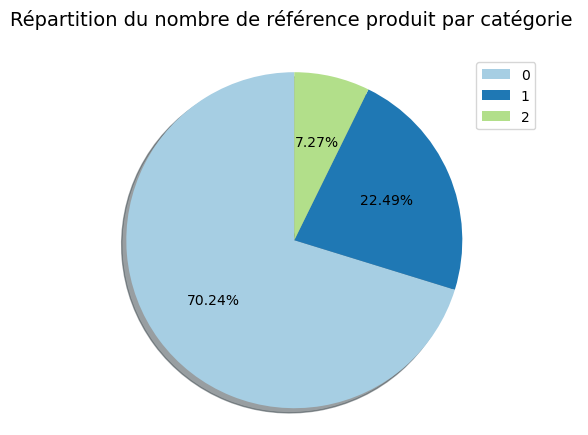

In [49]:
# Répartition des références produit par catégorie
# Calcul de la répartition des références par catégorie
Ref_categorie = product.groupby('categ')['id_prod'].count().reset_index()

# Renommer la colonne "id_prod" en "nb_prod"
Ref_categorie = Ref_categorie.rename(columns={"id_prod" : "nb_prod"})

# Affichage de la répartition des références par catégorie dans un Pie chart
# Récupération des données
proportion = Ref_categorie['nb_prod'].values
labels = Ref_categorie['categ'].values

# Obtenir la réf de couleur à utiliser
col_map = plt.get_cmap('Paired')

# Création du graph
fig, ax = plt.subplots()
ax.pie(proportion, autopct='%1.2f%%', shadow=True, startangle=90, colors=col_map.colors)
ax.axis('equal')
plt.legend(labels)
plt.title('Répartition du nombre de référence produit par catégorie \n', fontsize=14)

# Afficher le graph
plt.show()

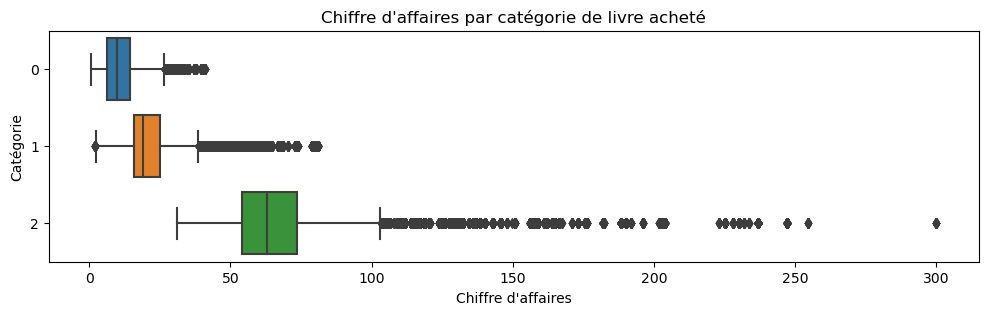

In [50]:
# Chiffre d'affaires par catégorie de livre acheté (BOXPLOT)
plt.figure(figsize=(12, 3))
sns.boxplot(y='categ', x='price', data=df, orient='h')
plt.title('Chiffre d\'affaires par catégorie de livre acheté')
plt.ylabel('Catégorie')
plt.xlabel('Chiffre d\'affaires')
plt.show()

+ La catégorie "0" représente 70.24% de nos produits pourtant il ne rapporte pas assez de chiffre d'affaires par rapport aux autres catégories de livre.
+ La catégorie "1" représente 40,14% du chiffre d'affaires. Pourtant, en termes de répartition de référence par produit, on a que 22.49% des produits qui sont de catégorie "1"

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Etape 5 - Analyse plus ciblée sur les clients (Julie)</h2>
</div>

# Profil client


# Analyse univariée

In [51]:
# Moyenne d'âge
print("Moyenne d'âge = {:.0f} ans".format(customer['age'].mean()))

Moyenne d'âge = 46 ans


In [52]:
# Répartition par genre
customer_genre = customer.groupby('sex')['client_id'].count().reset_index()
customer_genre['proportion'] = (customer_genre['client_id'] / customer_genre['client_id'].sum())*100
customer_genre

,sex,client_id,proportion
0,f,4490,52.082125
1,m,4131,47.917875


In [53]:
# Calcul du panier moyen 
# Calcul du CA par session pour avoir le montant d'un panier
CA_panier = df.groupby('session_id')[['price']].sum().reset_index()

# Affichage du panier moyen
print("Panier moyen = {:.0f} €".format(CA_panier['price'].mean()))

Panier moyen = 35 €


In [54]:
# Calcul du nombre d'achat moyen par client
CA_nb_achat = df.groupby('client_id')[['session_id']].nunique().reset_index()

# Affichage du nombre d'achat moyen par client
print("Nombre d'achat moyen par client= {:.0f} ".format(CA_nb_achat['session_id'].mean()))

Nombre d'achat moyen par client= 40 


In [55]:
# Top 10 des clients acheteurs
CA_client = df.groupby('client_id')[['price']].sum().reset_index()
CA_client = CA_client.sort_values(by='price', ascending=False)
Top10_client = CA_client.head(10)

<Figure size 700x500 with 0 Axes>

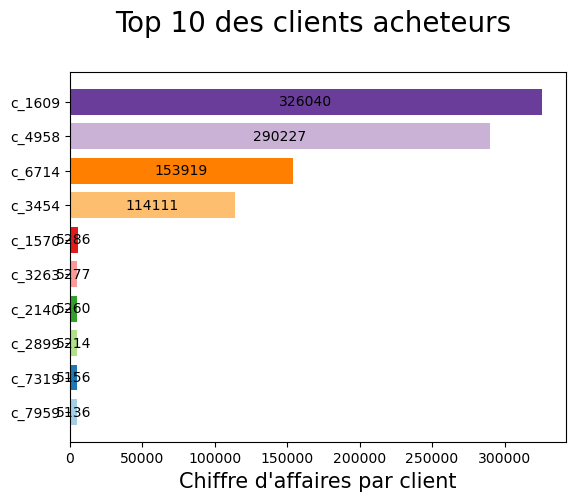

In [56]:
# Affichage des Top 10 clients acheteurs dans un graphique à barre horizontale
Top10_client = Top10_client.sort_values(by='price', ascending=True)

client = Top10_client['client_id'].values
CA = Top10_client['price'].values

# Ajuster la taille de l'image et obtenir la réf de couleur à utiliser
plt.figure(figsize=[7,5])
col_map = plt.get_cmap('Paired')

# Création du graphique avec titre,légende des axes et étiquettes des données
fig, ax = plt.subplots()
hbars = plt.barh(client,CA , height=0.75, color=col_map.colors)
ax.set_xlabel("Chiffre d'affaires par client", fontsize=15)
ax.set_title("Top 10 des clients acheteurs \n", fontsize=20)
ax.bar_label(hbars, fmt='%.0f', label_type='center')

# Afficher le graph
plt.show()


+ Il y a une grande différence entre les TOP 4 clients et le reste du TOP 10. Il se peut qu'ils soient des revendeurs/grossistes. Le reste sont des clients particuliers.

# Courbe de Lorenz

# Tous clients confondus

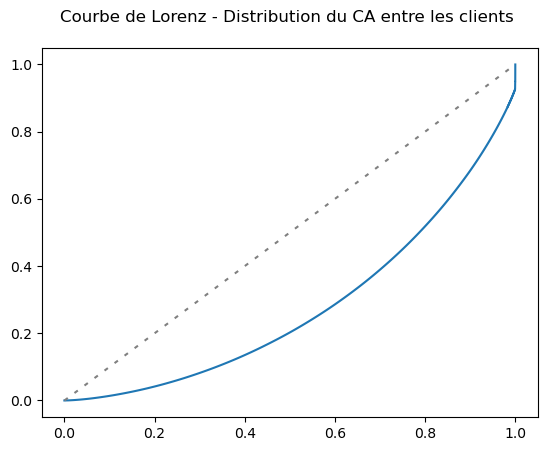

In [57]:
# Courbe de lorenz - Distribution du CA par client
# Calcul du CA par client
CA_client = df.groupby('client_id')[['price']].sum().reset_index()

# Renommer price en CA
CA_client = CA_client.rename(columns={"price" : "CA"})

# Prendre les CA>0 pour éviter l'erreur de division par 0
CA_client = CA_client[CA_client['CA'] > 0]
CA_client = CA_client['CA'].values
n = len(CA_client)

lorenz = np.cumsum(np.sort(CA_client)) / CA_client.sum()
lorenz = np.append([0],lorenz) # La courbe de Lorenz commence à 0

# Il y a un segment de taille n pour chaque individu, plus 1 segment supplémentaire d'ordonnée 0. 
# Le premier segment commence à 0-1/n, et le dernier termine à 1+1/n.
xaxis = np.linspace(0-1/n,1+1/n,n+1) 

# Tracer la courbe de Lorenz
plt.plot(xaxis,lorenz,drawstyle='steps-post')
plt.plot(np.linspace(0,1,len(lorenz)), np.linspace(0,1,len(lorenz)), color ="grey", dashes=[2,4]) # Ligne d'égalité parfaite
plt.title("Courbe de Lorenz - Distribution du CA entre les clients \n")

# Affichage du diagramme
plt.show()

In [58]:
# Calcul Indice de Gini
AUC = (lorenz.sum() -lorenz[-1]/2 -lorenz[0]/2)/n # Surface sous la courbe de Lorenz. Le premier segment (lorenz[0]) est à moitié en dessous de 0, on le coupe donc en 2, on fait de même pour le dernier segment lorenz[-1] qui est à moitié au dessus de 1.
S = 0.5 - AUC # Surface entre la première bissectrice et le courbe de Lorenz

print("Indice de gini = {:.2f} ".format(2*S))

Indice de gini = 0.44 


+ La pointe de la courbe de Lorenz peut s'expliquer par la présence du TOP4 acheteurs dans la base
+ Pour la suite de l'analyse, nous allons isoler les 4 clients qui ont un comportement professionnel
+ L'indice de Gini se rapproche de 0 => Distribution quasi égalitaire

# Clients particuliers

In [59]:
# Courbe de Lorenz des clients particuliers
# Enlever les clients pro
filtre = ~df['client_id'].isin(["c_1609","c_4958","c_6714","c_3454"])
df_particulier = df[filtre]

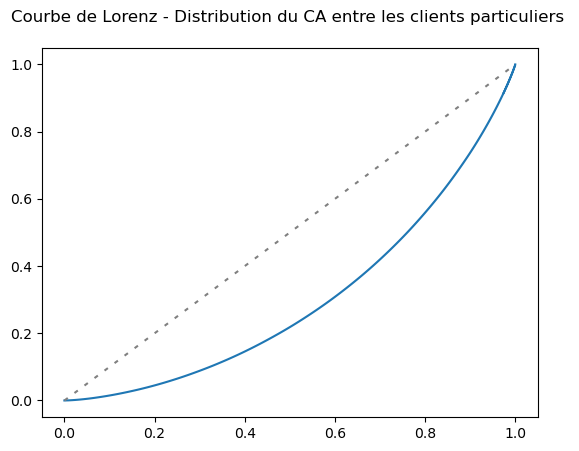

In [60]:
# Courbe de lorenz - Distribution du CA par client particulier
# Calcul du CA par client
CA_client = df_particulier.groupby('client_id')[['price']].sum().reset_index()

# Renommer price en CA
CA_client = CA_client.rename(columns={"price" : "CA"})

# Prendre les CA>0 pour éviter l'erreur de division par 0
CA_client = CA_client[CA_client['CA'] > 0]
CA_client = CA_client['CA'].values
n = len(CA_client)

lorenz = np.cumsum(np.sort(CA_client)) / CA_client.sum()
lorenz = np.append([0],lorenz) # La courbe de Lorenz commence à 0

# Il y a un segment de taille n pour chaque individu, plus 1 segment supplémentaire d'ordonnée 0. 
# Le premier segment commence à 0-1/n, et le dernier termine à 1+1/n.
xaxis = np.linspace(0-1/n,1+1/n,n+1) 

# Tracer la courbe de Lorenz
plt.plot(xaxis,lorenz,drawstyle='steps-post')
plt.plot(np.linspace(0,1,len(lorenz)), np.linspace(0,1,len(lorenz)), color ="grey", dashes=[2,4]) # Ligne d'égalité parfaite
plt.title("Courbe de Lorenz - Distribution du CA entre les clients particuliers \n")

# Affichage du diagramme
plt.show()



In [61]:
# Calcul Indice de Gini - Clients particuliers
AUC = (lorenz.sum() -lorenz[-1]/2 -lorenz[0]/2)/n # Surface sous la courbe de Lorenz. Le premier segment (lorenz[0]) est à moitié en dessous de 0, on le coupe donc en 2, on fait de même pour le dernier segment lorenz[-1] qui est à moitié au dessus de 1.
S = 0.5 - AUC # Surface entre la première bissectrice et le courbe de Lorenz

print("Indice de gini = {:.2f} ".format(2*S))

Indice de gini = 0.40 


L'indice de Gini se rapproche de 0 => Distribution de plus en plus égalitaire

Pour la suite de l'exercice, nous allons nous focaliser sur les données des clients particuliers c'est-à-dire "df_particulier"

# Analyse bivariée

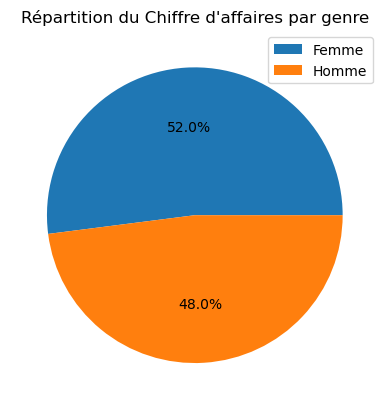

In [62]:
# Répartition du CA par genre
CA_genre = df_particulier.groupby('sex')[['price']].sum().reset_index()
# Renommer price en CA
CA_genre = CA_genre.rename(columns={"price" : "CA"})

# Création du diagramme circulaire
plt.pie(CA_genre['CA'].values, autopct='%1.1f%%')

# Ajout d'un titre
plt.title("Répartition du Chiffre d'affaires par genre")
plt.legend(['Femme','Homme'])

# Affichage du diagramme
plt.show()


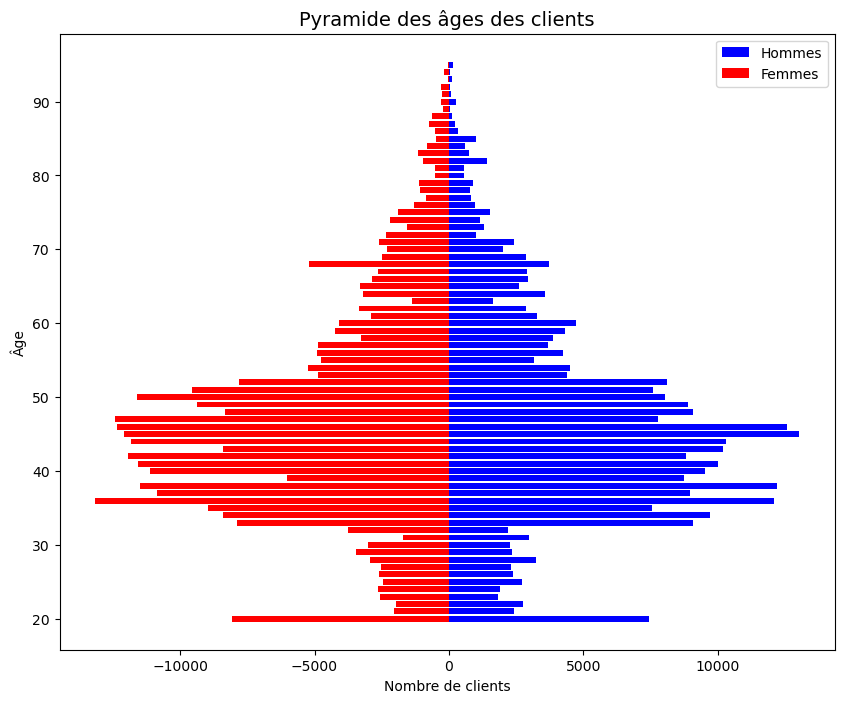

In [63]:
# Pyramide des âges, Genre x Age
# Séparer les données par sexe
hommes = df_particulier[df_particulier['sex'] == 'm']
femmes = df_particulier[df_particulier['sex'] == 'f']

# Compter le nombre de personnes pour chaque âge
hommes_counts = hommes['age'].value_counts().sort_index()
femmes_counts = femmes['age'].value_counts().sort_index()

# Créer la pyramide des âges
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(hommes_counts.index, hommes_counts, color='blue', label='Hommes', align='center')
ax.barh(femmes_counts.index, -femmes_counts, color='red', label='Femmes', align='center')
ax.set_xlabel('Nombre de clients')
ax.set_ylabel('Âge')
ax.legend()

plt.title('Pyramide des âges des clients', fontsize=14)

plt.show()

On peut dire que le chiffre d'affaires par genre est bien équilibré entre homme et femme

# 1.  Lien entre le genre d’un client et les catégories des livres achetés¶

In [64]:
# Table de contingence pour Chi²:
sex_categ = pd.crosstab(df_particulier["sex"],df_particulier["categ"])
sex_categ

categ,0,1,2
sex,,,
f,200793,115721,16980
m,186488,104884,15868


In [65]:
# Test de Chi²:
sc_chi2, sc_p, sc_dof, sc_expected = st.chi2_contingency(sex_categ)

# Afficher le résultat
print("Le tableau des fréquences attendues sont:\n", sc_expected)

print(f"\nCe qui donne un X² de {sc_chi2:.3f} à", sc_dof, "degré de liberté")
print("Soit une p-value de", sc_p)

Le tableau des fréquences attendues sont:
 [[201574.89662481 114822.13191434  17096.97146086]
 [185706.10337519 105782.86808566  15751.02853914]]

Ce qui donne un X² de 22.669 à 2 degré de liberté
Soit une p-value de 1.1955928116587024e-05


In [66]:
# Calcul V de Cramer:
n_sc = len(df_particulier)

V_sc = np.sqrt(sc_chi2/n_sc*sc_dof)
print("Le V de Cramer vaut:", V_sc)


Le V de Cramer vaut: 0.008411784594713622


+ Hypohtèse nulle : le genre du client est indépendant des catégories des livres achetés. Ce dernier est rejetée car p-value est largement inférieur à 0.05. 
+ Le V de Cramer est peu significatif donc, nous pouvons dire qu'il y a une très faible association entre le genre d'un client et les catégories des livres achetés.

Text(0.5, 1.0, 'Répartition du CA par genre et par catégorie de livre acheté\n')

<Figure size 800x500 with 0 Axes>

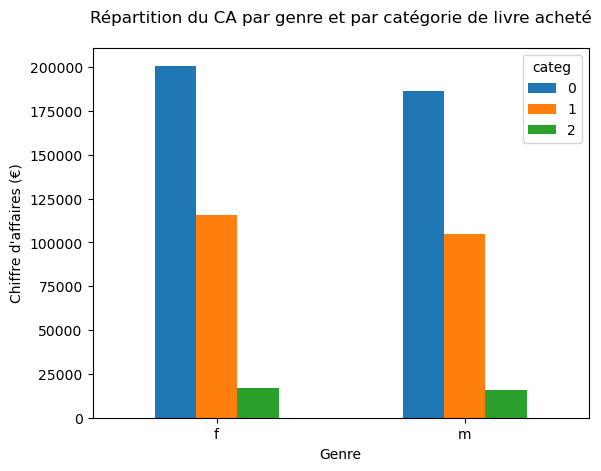

In [67]:
# Genre d’un client et Catégories des livres achetés (Histogramme)
sex_categ = sex_categ.reset_index()
plt.figure(figsize = (8,5))
sex_categ.plot.bar(x='sex')
plt.ylabel("Chiffre d'affaires (€)")
plt.xlabel('Genre')
plt.xticks(rotation=0)

plt.title("Répartition du CA par genre et par catégorie de livre acheté\n")

# 2. Lien entre l'âge des clients et le montant total des achats

Text(0.5, 1.0, "Chiffre d'affaires par âges")

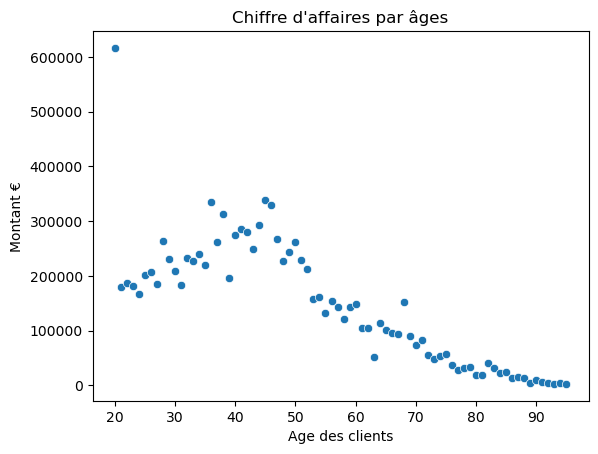

In [68]:
# Chiffre d'affaires par âge
achats_age = df_particulier.groupby(['age'])['price'].sum()

sns.scatterplot(data= achats_age)
plt.ylabel('Montant €')
plt.xlabel('Age des clients')
plt.title("Chiffre d'affaires par âges")

+ A première vue, il semble y avoir un lien entre l'âge des clients et le montant total des achats. Cependant, nous allons  le vérifier par un test statistique

In [69]:
# Test de normalité de Kolmogorov-Smirnov sur la colonne d'âge
ks_stat_age, p_value_age = kstest(df_particulier['age'], 'norm')


print("Résultats pour la colonne 'age':")
print("Statistique de test:", ks_stat_age)
print("Valeur p:", p_value_age)

# Test de normalité de Kolmogorov-Smirnov sur la colonne de prix
ks_stat_price, p_value_price = kstest(df_particulier['price'], 'norm')
print("Résultats pour la colonne 'price':")
print("Statistique de test:", ks_stat_price)
print("Valeur p:", p_value_price)

Résultats pour la colonne 'age':
Statistique de test: 1.0
Valeur p: 0.0
Résultats pour la colonne 'price':
Statistique de test: 0.9963826616381434
Valeur p: 0.0


+ La statistique de test est de 1.0 pour les deux colonnes, ce qui indique la plus grande différence observée entre la distribution empirique des données et la distribution normale théorique.

+ La valeur p est de 0.0 pour les deux colonnes, ce qui suggère que les données ne suivent pas une distribution normale. Une valeur p inférieure à 0.05 indique un rejet de l'hypothèse nulle selon laquelle les données suivent une distribution normale.

+ Puisque les 2 variables ne suivent pas une distribution normale, nous allons faire un test non paramétrique pour vérifier le lien entre eux.

In [70]:
# Test de corrélation de Spearman entre l'âge des clients et le montant total des achats
achats_age = achats_age.reset_index()
df_particulier.groupby(['age'])['price'].sum()
correlation, p_value = spearmanr(achats_age['age'], achats_age['price'])

print("Coefficient de corrélation :", correlation)
print("P-value:", p_value)

Coefficient de corrélation : -0.8744497607655503
P-value: 5.956077505475151e-25


+ Hypothèse nulle : il n'y a pas de lien entre l'âge des clients et le montant total des achats

+ Le coefficient de corrélation de -0.87 indique une forte corrélation négative entre l'âge des clients et le montant total des achats. Cela signifie que, en général, à mesure que l'âge augmente, le montant total des achats tend à diminuer.

+ P-value est largement inférieur à 0.05 donc l'hypothèse nulle est rejetée. Il y a bien une forte corrélation négative entre les 2 variables.

# 3. Lien entre l'âge des clients et la taille du panier moyen

Text(0.5, 1.0, 'Taille du panier moyen')

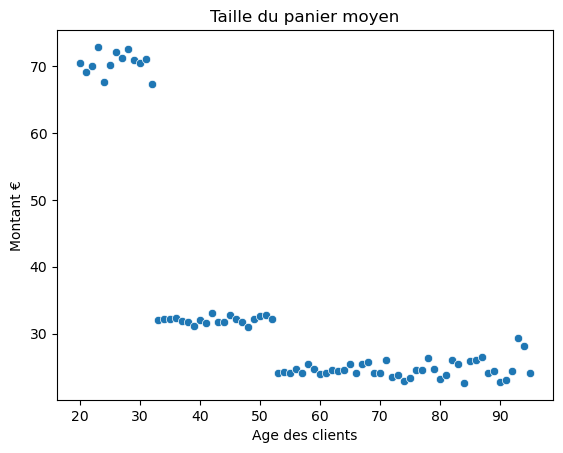

In [71]:
# Panier moyen par âge 
taille_panier = df_particulier.groupby(['age','session_id'])["price"].sum().reset_index()
panier_moyen = taille_panier.groupby(['age'])["price"].mean()

sns.scatterplot(data= panier_moyen)
plt.ylabel('Montant €')
plt.xlabel('Age des clients')
plt.title("Taille du panier moyen")

+ A première vue, plus l'âge monte, plus la taille du panier moyen diminue. De plus, il y a une grande différence entre chaque tranche d'âge. Néanmoins, nous allons procéder par un test statistique pour prouver ce lien.

In [72]:
# Test de normalité de Kolmogorov-Smirnov sur la colonne panier moyen
panier_moyen = panier_moyen.reset_index()
ks_stat_panier, p_value_panier= kstest(panier_moyen['price'].values, 'norm')
print("Statistique de test:", ks_stat_panier)
print("Valeur p:", p_value_panier)


Statistique de test: 1.0
Valeur p: 0.0


+ La variable ne suit pas la loi normale, donc on va faire un test de corrélation non paramétrique

In [73]:
# Test de corrélation de Spearman entre l'âge des clients et la fréquence d'achat
correlation, p_value = spearmanr(panier_moyen['age'], panier_moyen['price'])

print("Coefficient de corrélation :", correlation)
print("P-value:", p_value)

Coefficient de corrélation : -0.7824196855775802
P-value: 7.049554602185417e-17


+ Hypothèse nulle : Il n'y a pas de lien entre l'âge des clients et la taille du panier moyen

+ Le coefficient de corrélation de -0.78 indique une corrélation négative forte entre l'âge et la taille du panier moyen. Cela signifie que plus l'âge augmente, plus la taille du panier moyen diminue, et vice versa. La valeur absolue élevée du coefficient de corrélation indique une relation linéaire inversement proportionnelle entre les deux variables.

+ La p-value très faible (7.04e-17) suggère que cette corrélation est statistiquement significative. En d'autres termes, il est peu probable que cette corrélation soit due au hasard. Ainsi, nous pouvons conclure qu'il existe une corrélation significative et inverse entre l'âge et la taille du panier moyen.

# 4. Lien entre l'âge des clients et la catégorie des livres achetés

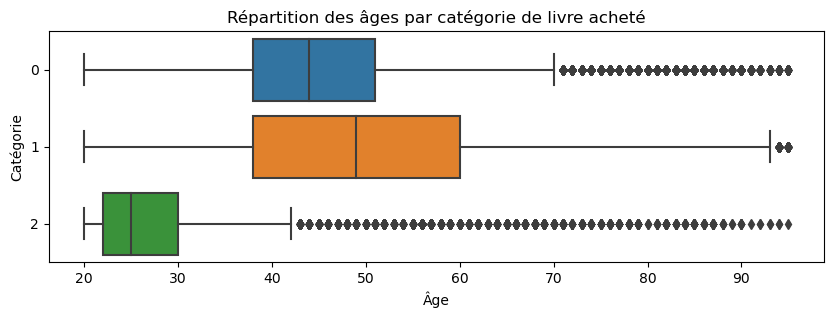

In [74]:
# Répartition des âges par catégorie de livre acheté (BOXPLOT)
plt.figure(figsize=(10, 3))
sns.boxplot(y='categ', x='age', data=df, orient='h')
plt.title('Répartition des âges par catégorie de livre acheté')
plt.ylabel('Catégorie')
plt.xlabel('Âge')
plt.show()

A première vue, il y a une tendance à confirmer entre l'âge des clients et la catégorie des livres achetés :
+ Les clients entre 40 et 50 ans ont tendance à acheter les livres de catégorie "0"
+ Les clients entre 40 et 60 ans ont tendance à acheter les livres de catégorie "1"
+ Les clients entre 20 et 30 ans ont tendance à acheter les livres de catégorie "2"

+ Précédemment, on a vu que l'âge des clients ne suit pas la loi normale, donc on va faire un test non paramétrique

In [75]:
# Test de Kruskal-Wallis
age_categ = df_particulier
Tkruskal = age_categ[['age', 'categ']]
g0 = Tkruskal[Tkruskal['categ']==0]['age'] 
g1 = Tkruskal[Tkruskal['categ']==1]['age'] 
g2 = Tkruskal[Tkruskal['categ']==2]['age'] 
stat, pvalue = kruskal(g0, g1, g2) 

# Affichage du résultat
print("Statistique de Kruskal-Wallis :", stat)
print("p-value :", pvalue)

Statistique de Kruskal-Wallis : 71359.73412120914
p-value : 0.0


+ Hypothèse nulle : Il n'y a pas de lien entre l'âge des client et les catégories de livre acheté
+ P-value est inférieur à 0.05 donc cette hypothèse est rejetée. 
+ Nous pouvons dire qu'il y a lien significatif entre la catégorie de livre acheté et l'âge des clients car la statistique de Kruskal-Wallis est élevée.

<div style="background-color: RGB(0,150,250);" >
<h2 style="margin: auto; padding: 20px; color:#fff; ">Recommandations</h2>
</div>

+ Faire une étude spécifique sur les produits qui n’ont jamais été vendu et les clients qui n’ont rien acheté

+ Faire une segmentation client, par exemple Particulier et B2B pour adapter le prix et la communication marketing afin de mettre en place une politique de fidélisation des clients 

+ Vérifier s’il n’y a pas eu de rétraction parmi les ventes effectuées par exemple à la suite d'une erreur de commande, surtout pour les jeunes (Lien significatif entre âge et montant total des achats)

+ Comme l'âge moyenne de notre clientèle est de 46 ans, il faut prévoir des actions marketings pour inciter les clients entre 40 et 60 ans à faire des achats. Par exemple, nous pourrions mettre en avant les livres de catégorie 1 qui pourraient les intéressées.

+ Anticiper les ruptures de stock afin de maintenir le chiffre d'affaires, surtout ceux de nos produits phares à savoir les livres de catégorie 2

#  ----------------------- FIN ----------------------------- Merci ----------------------